# MaintSense: AI4I 2020 data exploration

This notebook explores the AI4I 2020 Predictive Maintenance dataset before any modeling. It checks data quality, class balance, feature distributions, feature/failure relationships, and target leakage risks. No model is trained here.

> Run from the project root with the project dependencies installed. The path below is relative to this notebook (`notebooks/`). The raw CSV is intentionally excluded from Git.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

# Jupyter may start its kernel from the project root or the notebooks folder.
NOTEBOOK_DIR = Path.cwd() / "notebooks" if (Path.cwd() / "notebooks").is_dir() else Path.cwd()
DATA_PATH = NOTEBOOK_DIR / "../data/raw/ai4i+2020+predictive+maintenance+dataset/ai4i2020.csv"
TARGET = "Machine failure"
MODE_COLUMNS = ["TWF", "HDF", "PWF", "OSF", "RNF"]

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Place the downloaded AI4I CSV there."
    )
df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Loaded C:\Projects\MaintSense\notebooks\..\data\raw\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv: 10,000 rows × 14 columns


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Schema and data quality

In [2]:
print("Shape:", df.shape)
print("Columns:")
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values}))
df.info()

Shape: (10000, 14)
Columns:


,column,dtype
0,UDI,int64
1,Product ID,str
2,Type,str
3,Air temperature [K],float64
4,Process temperature [K],float64
5,Rotational speed [rpm],int64
6,Torque [Nm],float64
7,Tool wear [min],int64
8,Machine failure,int64
9,TWF,int64


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [3]:
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
display(quality.sort_values("missing_count", ascending=False))
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
print(f"Duplicate Product ID values: {df['Product ID'].duplicated().sum():,}")

,missing_count,missing_percent
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


Exact duplicate rows: 0
Duplicate Product ID values: 0


In [4]:
display(df.describe(include="all").T)
print("Target value counts (including missing):")
display(df[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("count"))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


Target value counts (including missing):


,count
Machine failure,
0,9661
1,339


## Target balance

,count,fraction
Machine failure,,
0,9661,0.9661
1,339,0.0339


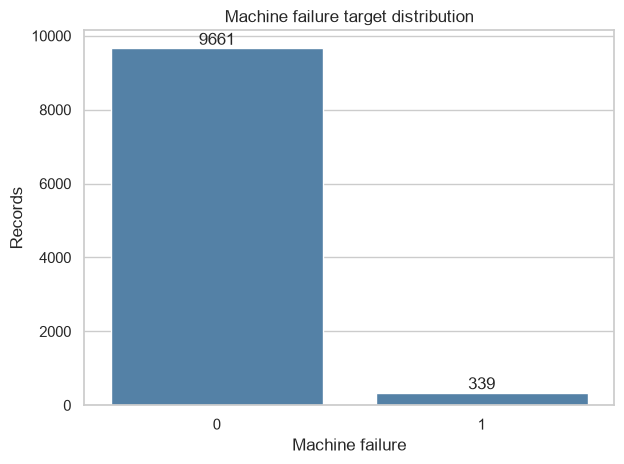

In [5]:
target_counts = df[TARGET].value_counts(dropna=False).sort_index()
display(pd.DataFrame({"count": target_counts, "fraction": (target_counts / len(df)).round(4)}))
ax = sns.countplot(data=df, x=TARGET, order=target_counts.index, color="steelblue")
ax.set(title="Machine failure target distribution", xlabel="Machine failure", ylabel="Records")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

## Numerical feature distributions

Identifiers and binary indicators are excluded from these continuous-feature plots. Review the schema above when interpreting numeric-looking columns such as product type or failure indicators.

Continuous numeric columns plotted: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


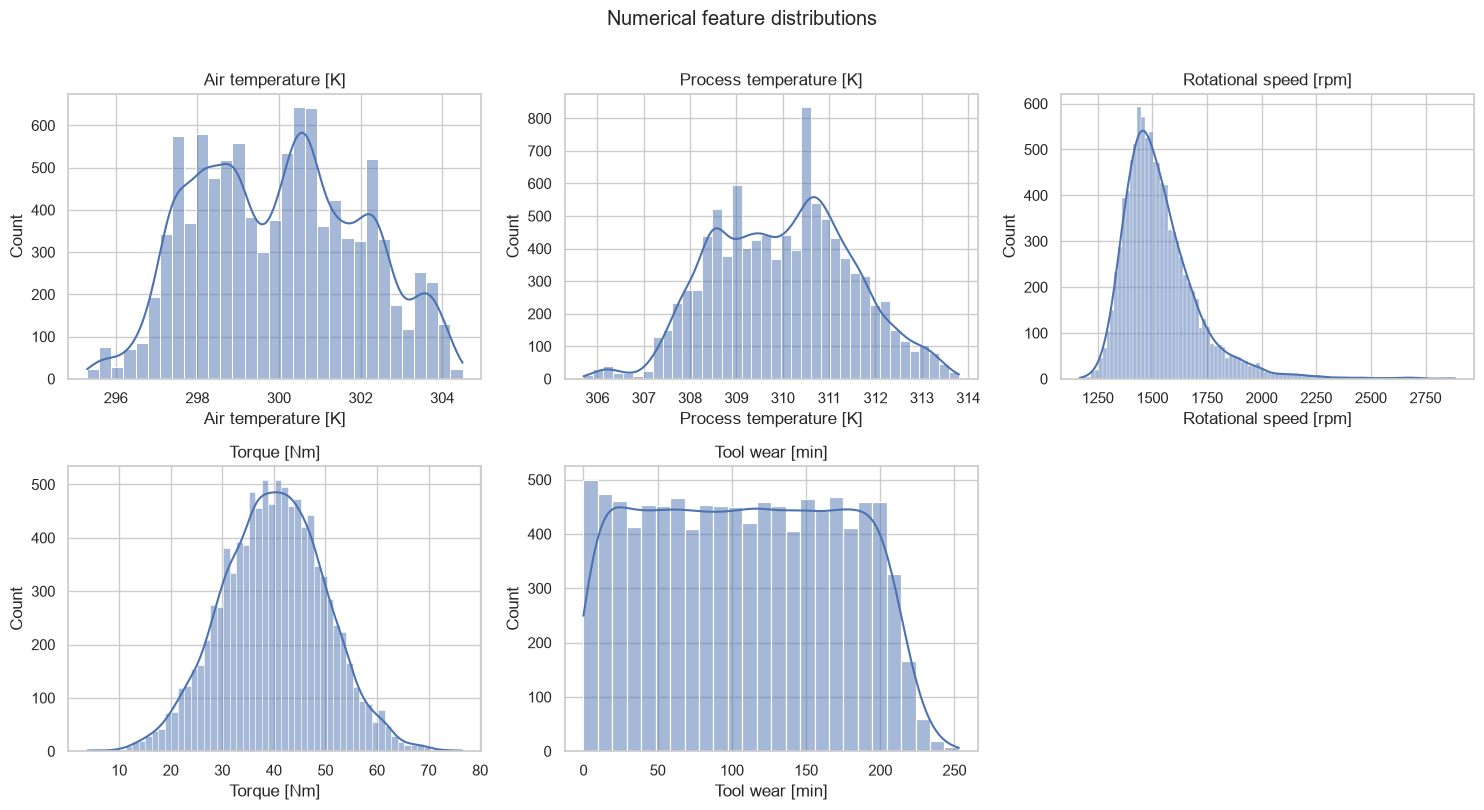

In [6]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
exclude_from_continuous = {TARGET, "UDI", "Product ID", *MODE_COLUMNS}
continuous_columns = [c for c in numeric_columns if c not in exclude_from_continuous]
print("Continuous numeric columns plotted:", continuous_columns)
ncols = 3
nrows = int(np.ceil(len(continuous_columns) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.asarray(axes).reshape(-1)
for ax, column in zip(axes, continuous_columns):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(column)
for ax in axes[len(continuous_columns):]:
    ax.remove()
fig.suptitle("Numerical feature distributions", y=1.01)
fig.tight_layout()
plt.show()

## Feature relationships with machine failure

Compare distributions and observed failure rates descriptively. These are exploratory associations, not causal effects or an estimate of future performance.

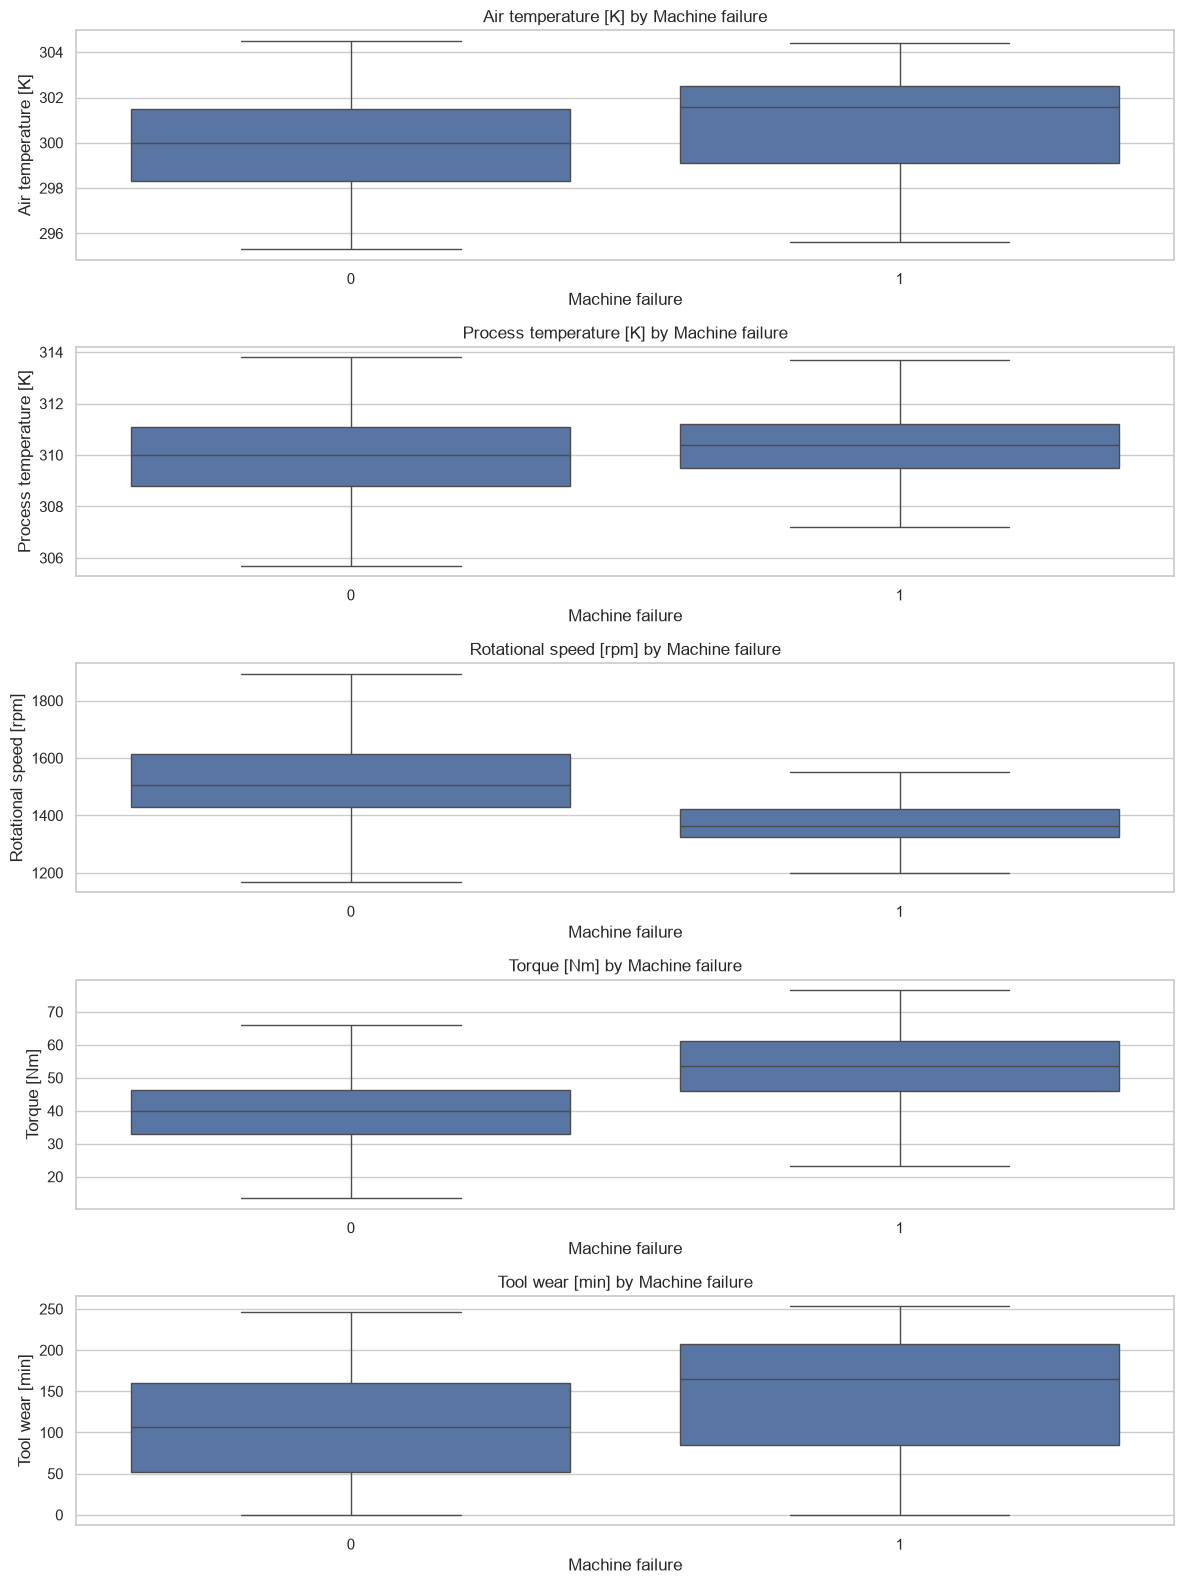

In [7]:
fig, axes = plt.subplots(len(continuous_columns), 1, figsize=(12, 3.2 * len(continuous_columns)))
axes = np.atleast_1d(axes)
for ax, column in zip(axes, continuous_columns):
    sns.boxplot(data=df, x=TARGET, y=column, ax=ax, showfliers=False)
    ax.set_title(f"{column} by {TARGET}")
fig.tight_layout()
plt.show()

,records,failures,failure_rate
Type,,,
H,1003,21,0.020937
L,6000,235,0.039167
M,2997,83,0.027694


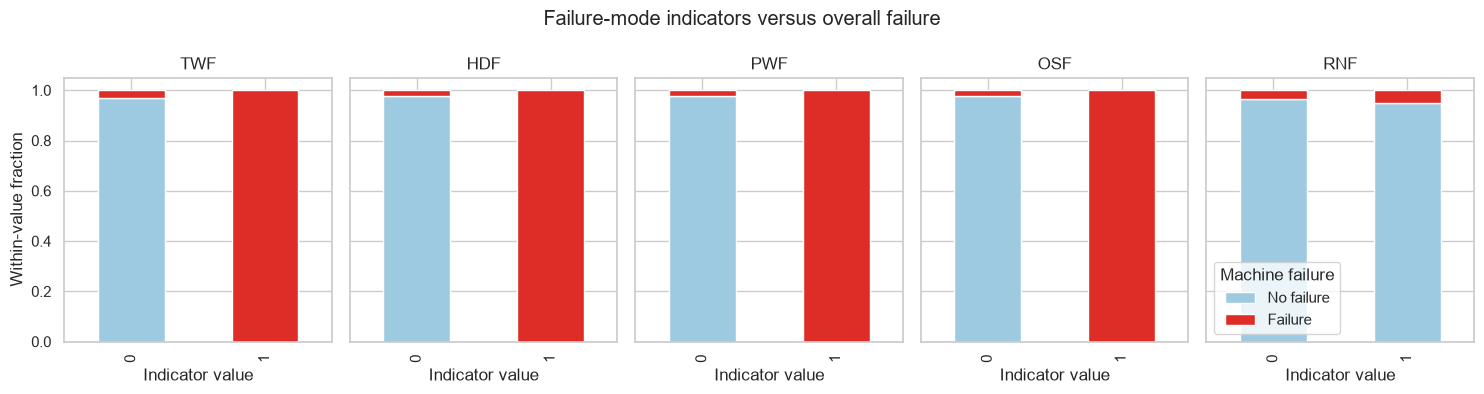

In [8]:
# Numeric values here are summaries, not inferential statistics.
failure_rates = (df.groupby("Type", dropna=False)[TARGET]
                 .agg(records="size", failures="sum", failure_rate="mean")
                 .sort_index())
display(failure_rates)

fig, axes = plt.subplots(1, len(MODE_COLUMNS), figsize=(15, 4), sharey=True)
for ax, column in zip(axes, MODE_COLUMNS):
    counts = pd.crosstab(df[column], df[TARGET], normalize="index")
    counts.plot(kind="bar", stacked=True, ax=ax, legend=False, color=["#9ecae1", "#de2d26"])
    ax.set(title=column, xlabel="Indicator value", ylabel="Within-value fraction")
axes[-1].legend(title=TARGET, labels=["No failure", "Failure"])
fig.suptitle("Failure-mode indicators versus overall failure")
fig.tight_layout()
plt.show()

## Leakage and prediction-time audit

The mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) describe failure modes and may be recorded as part of, or after, a failure event. Their association with `Machine failure` can therefore encode the label directly. Exclude them from candidate predictors unless their availability before the prediction decision is established.

`UDI` and `Product ID` are identifiers rather than operational measurements and should not be treated as ordinary predictors. `Type` is a categorical product grade, even if encoded as text. Confirm how each field is generated and when it becomes available in the intended deployment workflow before defining a feature set. A random row split may also overstate future performance if records share machines or time-dependent structure; this dataset's sampling design should be checked.

In [9]:
present_modes = [column for column in MODE_COLUMNS if column in df.columns]
print("Failure-mode indicator counts:")
display(df[present_modes].sum().rename("positive_records").to_frame())
if TARGET in df and present_modes:
    print("Cross-tabulation against overall failure (inspect for deterministic overlap):")
    for column in present_modes:
        display(pd.crosstab(df[column], df[TARGET], margins=True))

candidate_features = [c for c in df.columns if c not in {TARGET, "UDI", "Product ID", *MODE_COLUMNS}]
print("Provisional feature candidates pending prediction-time review:", candidate_features)

Failure-mode indicator counts:


,positive_records
TWF,46
HDF,115
PWF,95
OSF,98
RNF,19


Cross-tabulation against overall failure (inspect for deterministic overlap):


Machine failure,0,1,All
TWF,,,
0,9661,293,9954
1,0,46,46
All,9661,339,10000


Machine failure,0,1,All
HDF,,,
0,9661,224,9885
1,0,115,115
All,9661,339,10000


Machine failure,0,1,All
PWF,,,
0,9661,244,9905
1,0,95,95
All,9661,339,10000


Machine failure,0,1,All
OSF,,,
0,9661,241,9902
1,0,98,98
All,9661,339,10000


Machine failure,0,1,All
RNF,,,
0,9643,338,9981
1,18,1,19
All,9661,339,10000


Provisional feature candidates pending prediction-time review: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


## Findings and unresolved questions

### Observed findings
- The CSV has 10,000 rows and 14 columns. Every column has 10,000 non-null values; there are no exact duplicate rows or duplicate `Product ID` values.
- `Machine failure` is 1 for 339 rows (3.39%) and 0 for 9,661 rows (96.61%), so the target is strongly imbalanced. Accuracy alone would hide the low failure prevalence.
- The five plotted continuous measurements have ranges: air temperature 295.3–304.5 K, process temperature 305.7–313.8 K, rotational speed 1,168–2,886 rpm, torque 3.8–76.6 Nm, and tool wear 0–253 min. See the plots above for distribution shapes and comparisons.
- `TWF`, `HDF`, `PWF`, and `OSF` were positive only among failure rows (46/46, 115/115, 95/95, and 98/98, respectively). `RNF` was positive for 18 non-failure rows and 1 failure row. These are suspicious target proxies; confirm when these indicators become available before using any as predictors.
- Observed failure rates by Type were H: 21/1,003 (2.09%), L: 235/6,000 (3.92%), and M: 83/2,997 (2.77%). These descriptive rates do not establish causality or future performance.


### Findings to record
- Dataset dimensions, schema, and any missing or duplicate records:
- Target prevalence and class imbalance implications:
- Notable feature distribution shapes, ranges, or outliers:
- Descriptive differences associated with failure:
- Leakage indicators or suspiciously direct relationships:

### Unresolved questions
- Which columns are available at the actual decision time, before a failure?
- Are rows independent, or should a time-, machine-, or group-aware evaluation split be used?
- What is the operational definition and prediction horizon for a useful alert?
- Which error is more costly: missed failures or false alarms, and what lead time is required?
- Does the simulated dataset represent the deployment population and sensor conditions?

Accuracy alone cannot establish usefulness, especially if failures are uncommon. Later evaluation should consider class-sensitive metrics, calibration, alert burden, lead time, and a deployment-appropriate validation design.